(38338, 16)
   latitude  longitude  brightness  scan  track    acq_date  acq_time  \
0  36.66336 -120.13248      295.21  0.39   0.36  2025-01-01       956   
1  37.45582 -121.93400      297.58  0.39   0.36  2025-01-01       956   
2  37.88374 -121.18607      299.62  0.38   0.36  2025-01-01       956   
3  37.94431 -122.39557      301.16  0.39   0.36  2025-01-01       956   
4  37.95163 -122.39848      296.81  0.39   0.36  2025-01-01       956   

  satellite instrument confidence version  bright_t31   frp daynight  type  \
0      SNPP       SNPP          n       2      273.27  0.51        N   0.0   
1      SNPP       SNPP          n       2      275.72  0.35        N   2.0   
2      SNPP       SNPP          n       2      274.93  0.65        N   2.0   
3      SNPP       SNPP          n       2      277.94  1.27        N   2.0   
4      SNPP       SNPP          n       2      283.51  0.93        N   2.0   

  processing_source  
0           Archive  
1           Archive  
2           Ar

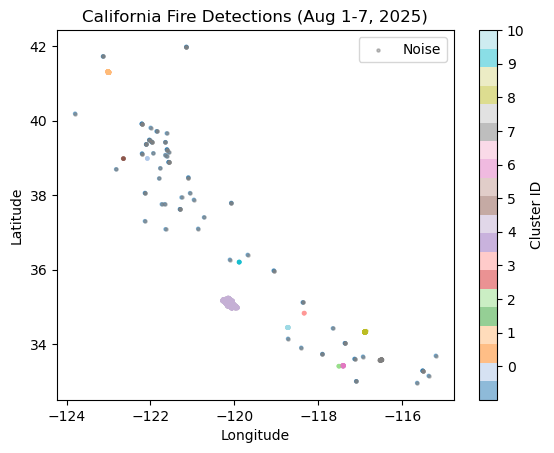

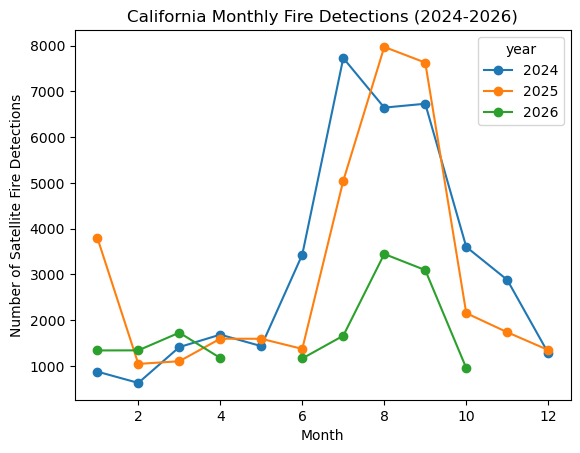

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import DBSCAN

df = pd.read_csv("data/FireWatch_California_VIIRS_SNPP_2025_2026_Combined.csv",
        low_memory=False
)
df_2024 = pd.read_csv(
    "data/FireWatch_california_2024.csv",
    low_memory=False
)
df_2024["processing_source"] = "Archive"

print(df_2024.shape)
print(df.head())
print(df.shape)
print(df.dtypes)
print(df.isnull().sum())
print(df.groupby("processing_source")["type"].apply(lambda x: x.isnull().sum()))
print(df.duplicated().sum())
print("Duplicate records:", df.duplicated().sum())
print(set(df.columns) - set(df_2024.columns))
print("Only in 2025-2026:")
print(set(df.columns) - set(df_2024.columns))

print("Only in 2024:")
print(set(df_2024.columns) - set(df.columns))
print("2024 shape:", df_2024.shape)
print("Same columns:", set(df_2024.columns) == set(df.columns))
df_combined = pd.concat([df_2024, df], ignore_index=True)
print("Combined shape:", df_combined.shape)
print("Combined duplicate records:", df_combined.duplicated().sum())
df_combined["acq_date"] = pd.to_datetime(
    df_combined["acq_date"],
    errors="coerce"
)
print("Date type:", df_combined["acq_date"].dtype)
print("Missing dates:", df_combined["acq_date"].isna().sum())
print("Earliest date:", df_combined["acq_date"].min())
print("Latest date:", df_combined["acq_date"].max())
df_combined["year"] = df_combined["acq_date"].dt.year
df_combined["month"] = df_combined["acq_date"].dt.month
print(df_combined[["acq_date", "year", "month"]].head())
monthly_counts = df_combined.groupby(["year", "month"]).size()
print(monthly_counts)
print("Maximum fire detections:", monthly_counts.max())
print("Peak year/month:", monthly_counts.idxmax())

cluster_data = df_combined[
    (df_combined["year"] == 2025) &
    (df_combined["month"] == 8)
].copy()

print("Clustering data shape:", cluster_data.shape)
print(cluster_data["type"].value_counts(dropna=False))

fire_data = cluster_data[cluster_data["type"] == 0].copy()
print("vegetation fire detections:", fire_data.shape)

coordinates = fire_data[["latitude", "longitude"]]
print(coordinates.head())
print("Coordinates shape:",coordinates.shape)
week_data = fire_data[
    (fire_data["acq_date"] >= "2025-08-01") &
    (fire_data["acq_date"] < "2025-08-08")
].copy()
print("Weekly fire directions:", week_data.shape)
weekly_coordinates = week_data[["latitude", "longitude"]]
print("Weekly coordinates shape:", weekly_coordinates.shape)

coordinates_rad = np.radians(weekly_coordinates)
eps_km = 5
earth_radius_km = 6371.0088
dbscan = DBSCAN(
    eps=eps_km / earth_radius_km,
    min_samples=5,
    metric="haversine",
    algorithm="ball_tree"
)
cluster_labels = dbscan.fit_predict(coordinates_rad)
print("label_count:", cluster_labels)
total_points = len(cluster_labels)
cluster_counts = pd.Series(cluster_labels).value_counts()
print("counts:",cluster_counts)
total_tables = len(cluster_counts)
n_clusters = total_tables - 1
print("Total clusters:", n_clusters)

noise_count = cluster_counts.loc[-1]
print("Total noise points:", noise_count)
noise_percentage = noise_count / total_points * 100
round_noise_percentage = round(noise_percentage, 2)
print("Noise percentage:", round_noise_percentage)

week_data["cluster_id"] = cluster_labels
print(week_data.head())
cluster_4 = week_data[week_data["cluster_id"] == 4].copy()
#print("cluster 4:", cluster_4)
print("Cluster 4 shape:", cluster_4.shape)
print("First 10 cluster labels:", cluster_labels[:10])
print("Coordinates in radians:")
print(coordinates_rad.head())

print("Maximum longitude:", cluster_4["longitude"].max())
print("Minimum longitude:", cluster_4["longitude"].min())
print("Maximum latitude:", cluster_4["latitude"].max())
print("Minimum latitude:", cluster_4["latitude"].min())
latitude_range = cluster_4["latitude"].max() - cluster_4["latitude"].min()
print("latitude_range:", latitude_range)
longitude_range = cluster_4["longitude"].max() - cluster_4["longitude"].min()
print("longitude_range:", longitude_range)

north_south_km = latitude_range * 111
north_south_distance = round(north_south_km, 2)
print("North and south distance:",north_south_distance)

mean_latitude = cluster_4["latitude"].mean()
mean_latitude_rad = np.radians(mean_latitude)
print("Mean latitude(radiance):", mean_latitude_rad)
west_east_km = longitude_range * 111 * np.cos(mean_latitude_rad)
west_east_distance = round(west_east_km, 2)
print("West-East distance:", west_east_distance, "km")

scatter_plot = plt.scatter(week_data["longitude"],
             
                            week_data["latitude"],
                            s=5,
                            alpha=0.5,
                            c=week_data["cluster_id"],
                            cmap="tab20"
                        )
cbar = plt.colorbar(scatter_plot)
plt.xlabel("Longitude")
cbar.set_label("Cluster ID")
cbar.set_ticks(range(0, 11))
noise_data = week_data[week_data["cluster_id"] == -1].copy()
plt.ylabel("Latitude")
non_noise_data = week_data[
    week_data["cluster_id"] != -1
].copy()
plt.scatter(
    noise_data["longitude"],
    noise_data["latitude"],
    s=5,
    alpha=0.5,
    color="gray",
    label="Noise"
)
plt.legend()
plt.title("California Fire Detections (Aug 1-7, 2025)")
plt.savefig("firewatch_dbscan_clusters.png", 
            dpi=300, 
            bbox_inches="tight"
)
plt.show()
monthly_counts.unstack(level=0).plot(marker="o")
plt.title("California Monthly Fire Detections (2024-2026)")
plt.xlabel("Month")
plt.ylabel("Number of Satellite Fire Detections")
plt.savefig("firewatch_monthly_trend.png", dpi=300, bbox_inches="tight")
plt.show()
